<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/linregr_predict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressione lineare: predizione per massima verosimiglianza, MAP e pienamente bayesiana

Questo notebook confronta i tre modi di predire con un modello lineare probabilistico discussi nelle note: la stima di **massima verosimiglianza** (ML), la stima **maximum a posteriori** (MAP) e la predizione **pienamente bayesiana**, che fornisce la distribuzione predittiva. I tre approcci usano lo stesso modello e gli stessi dati, e aggiungono via via un livello di ragionamento probabilistico.

## Il modello probabilistico

Il modello è lineare in un insieme di funzioni base, $h(x;\mathbf{w})=\mathbf{w}^T\boldsymbol\phi(x)$, e il target di un elemento è trattato come una variabile casuale centrata nella predizione del modello: il rumore, gli errori di misura e i fattori non modellati allontanano ogni osservazione dalla media. Con rumore gaussiano di **precisione** $\beta$ (inverso della varianza),
$$p(t\mid x,\mathbf{w},\beta)=\mathcal{N}\bigl(t\mid\mathbf{w}^T\boldsymbol\phi(x),\beta^{-1}\bigr).$$
Il modello specifica solo la distribuzione condizionata del target: la distribuzione degli elementi non dipende dai parametri e non ha alcun ruolo nella loro stima. Come visto nelle note, scegliere un modello probabilistico per il target equivale a scegliere una loss: la loss indotta dal modello gaussiano è $-\log p(t\mid x,\mathbf{w},\beta)=\frac\beta2(t-\mathbf{w}^T\boldsymbol\phi(x))^2+\text{cost.}$, cioè la loss quadratica.

## I tre approcci, in sintesi

| | Massima verosimiglianza | MAP | Pienamente bayesiano |
|---|---|---|---|
| Cosa si apprende | un vettore $\mathbf{w}_{ML}$ | un vettore $\mathbf{w}_{MAP}$, moda del posterior | l'intero posterior $p(\mathbf{w}\mid\mathbf{X},\mathbf{t})$ |
| Regolarizzazione | nessuna | prior gaussiano, equivalente a ridge con $\lambda=\alpha/\beta$ | prior gaussiano |
| Predizione | $\mathcal{N}(\mathbf{w}_{ML}^T\boldsymbol\phi(x),\beta_{ML}^{-1})$ | $\mathcal{N}(\mathbf{w}_{MAP}^T\boldsymbol\phi(x),\beta^{-1})$ | $\mathcal{N}(m(x),\sigma^2(x))$ |
| Incertezza | solo rumore, stimato sui residui | solo rumore | rumore e incertezza sui parametri |

Le prime celle preparano l'ambiente, le funzioni base e il dataset; seguono le tre predizioni e un confronto finale. Nell'ultima parte gli stessi tre approcci sono ripetuti con la **loss lineare**, cioè con rumore di **Laplace**, e confrontati con quelli della loss quadratica, anche su un dataset con outlier.

## Preparazione

In [1]:
%matplotlib inline
import numpy as np
import scipy.stats as st

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib import cm

sns.set_theme(style='whitegrid', palette='deep')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['image.cmap'] = 'jet'
plt.rcParams['image.interpolation'] = 'none'
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['lines.linewidth'] = 2


colors = ['xkcd:pale orange', 'xkcd:sea blue', 'xkcd:pale red', 'xkcd:sage green', 'xkcd:terra cotta', 'xkcd:dull purple', 'xkcd:teal', 'xkcd:goldenrod', 'xkcd:cadet blue', 
          'xkcd:scarlet']
cmap_big = plt.get_cmap('Spectral', 512)
cmap = mcolors.ListedColormap(cmap_big(np.linspace(0.7, 0.95, 256)))

bbox_props = dict(boxstyle="round,pad=0.3", fc=colors[0], alpha=.5)

## Le funzioni base

`vphi` costruisce la matrice di design: per ciascun valore di `x` calcola $d$ funzioni base gaussiane con varianza unitaria e centri nei punti medi di $d$ intervalli di uguale ampiezza in cui viene diviso il dominio (si noti che la funzione usa la variabile globale `domain` invece del parametro `dom`, che ha lo stesso valore). Non c'è una funzione base costante, quindi il modello non ha un termine di bias esplicito.

Con varianza unitaria su un dominio di ampiezza $2\pi$, le funzioni base sono piuttosto larghe e molto sovrapposte: ciascuna influenza le predizioni su una porzione ampia del dominio.

In [4]:
def vphi(x, d, dom):
    l = np.linspace(domain[0], domain[1], d+1)
    mus = [(l[i]+l[i+1])/2.0 for i in range(len(l)-1)]
    return np.array([gaussian_basis(x, mus[i], 1) for i in range(d)]).T

`gaussian_basis` è la funzione base gaussiana con media `m` e deviazione standard `s`.

In [5]:
def gaussian_basis(x, m, s):
    return np.exp(-((x-m)**2)/(2*s**2))

## Il dataset

Generiamo $n=10$ punti con $x$ uniforme in $[0,2\pi]$ e target $t=\sin(x)+\varepsilon$, con rumore gaussiano di deviazione standard $0.05$, e calcoliamo la matrice di design con $d=8$ funzioni base.

In [6]:
# dominio della feature
domain=(0,2*np.pi)
# numero di elementi da generare
n=10
# array delle feature generato uniformemente nel dominio
X=np.random.uniform(domain[0], domain[1], n)

# genera il vettore target mediante la funzione f e l'aggiunta di rumore gaussiano
# funzione 
def f(x):
    return np.sin(x)
# sd del rumore
noise = .05

#genera target
t=np.array([(f(v)+np.random.normal(0,noise,1))[0] for v in X]).reshape(-1,1)

# numero di funzioni base
d=8
# genera immagine di X per la regressione
Phi = vphi(X,d, domain)

## Gli iperparametri

Per MAP e per la predizione pienamente bayesiana servono due iperparametri, fissati qui a mano: la precisione del prior $\alpha=0.2$ e la precisione del rumore $\beta=50$, cioè una deviazione standard del rumore assunta pari a $1/\sqrt{50}\approx0.14$, più grande di quella effettiva ($0.05$, cioè $\beta=400$): il modello è più "prudente" del necessario. Nelle note si discute come stimare $\alpha$ e $\beta$ dai dati, con l'*evidence framework*. La massima verosimiglianza, invece, non usa un prior, e stima la precisione del rumore dai dati.

*Nota:* nella versione originale `alfa` era definito ma non usato (il posterior era calcolato con precisione del prior pari a $1$), e venivano definiti una media e una covarianza del prior di dimensione $d+1$, anch'esse inutilizzate. Il codice è stato corretto in modo che $\alpha$ sia effettivamente la precisione del prior.

In [7]:
# precisione del prior: p(w) = N(0, alfa^{-1} I)
alfa=.2

# parametro per la verosimiglianza
beta=50

## Il training set

Tutti e tre gli approcci usano i primi `l` elementi del dataset. Con `l = n = 10` si usano tutti; impostando `l` a un valore minore (ad esempio $2$ o $4$) i punti esclusi compaiono nei grafici con un colore diverso, e si può osservare come cambiano le tre predizioni quando i dati sono pochi.

In [8]:
# numero elementi considerati per il training
l=10
# estrazione del training set
X_t, t_t = Phi[:l,:], t[:l]

# griglia di valori per i grafici e corrispondente matrice di design
xx=np.linspace(min(X),max(X),500)
phix=vphi(xx,d,domain)

## Predizione per massima verosimiglianza

La **verosimiglianza** è la probabilità dei target osservati, vista come funzione dei parametri. Per elementi indipendenti, con residui $r_i=\mathbf{w}^T\boldsymbol\phi(x_i)-t_i$,
$$\log p(\mathbf{t}\mid\mathbf{X},\mathbf{w},\beta)=-\frac\beta2\sum_{i=1}^l r_i^2+\frac l2\log\beta-\frac l2\log(2\pi).$$
I parametri $\mathbf{w}$ compaiono solo nel primo termine: massimizzare la verosimiglianza rispetto a $\mathbf{w}$ equivale a minimizzare la somma dei quadrati dei residui, e $\mathbf{w}_{ML}$ è dato dalle **equazioni normali**,
$$\mathbf{w}_{ML}=(\boldsymbol\Phi^T\boldsymbol\Phi)^{-1}\boldsymbol\Phi^T\mathbf{t}:$$
i minimi quadrati sono la stima di massima verosimiglianza sotto rumore gaussiano. Annullando la derivata rispetto a $\beta$ si ottiene la stima della varianza del rumore,
$$\beta_{ML}^{-1}=\frac1l\sum_{i=1}^l r_i^2,$$
la media dei quadrati dei residui del modello stimato. La predizione è la distribuzione
$$p(t\mid x;\mathbf{w}_{ML},\beta_{ML})=\mathcal{N}\bigl(t\mid\mathbf{w}_{ML}^T\boldsymbol\phi(x),\beta_{ML}^{-1}\bigr):$$
un valore predetto, con una banda di incertezza di ampiezza **costante** su tutto il dominio.

Nel codice, $\mathbf{w}_{ML}$ è calcolato con `np.linalg.lstsq`, numericamente più stabile dell'inversione esplicita: con $8$ funzioni base gaussiane larghe e molto sovrapposte, la matrice $\boldsymbol\Phi^T\boldsymbol\Phi$ è mal condizionata.

deviazione standard stimata del rumore: 0.0115 (vera: 0.0500)
norma dei coefficienti: 7.90


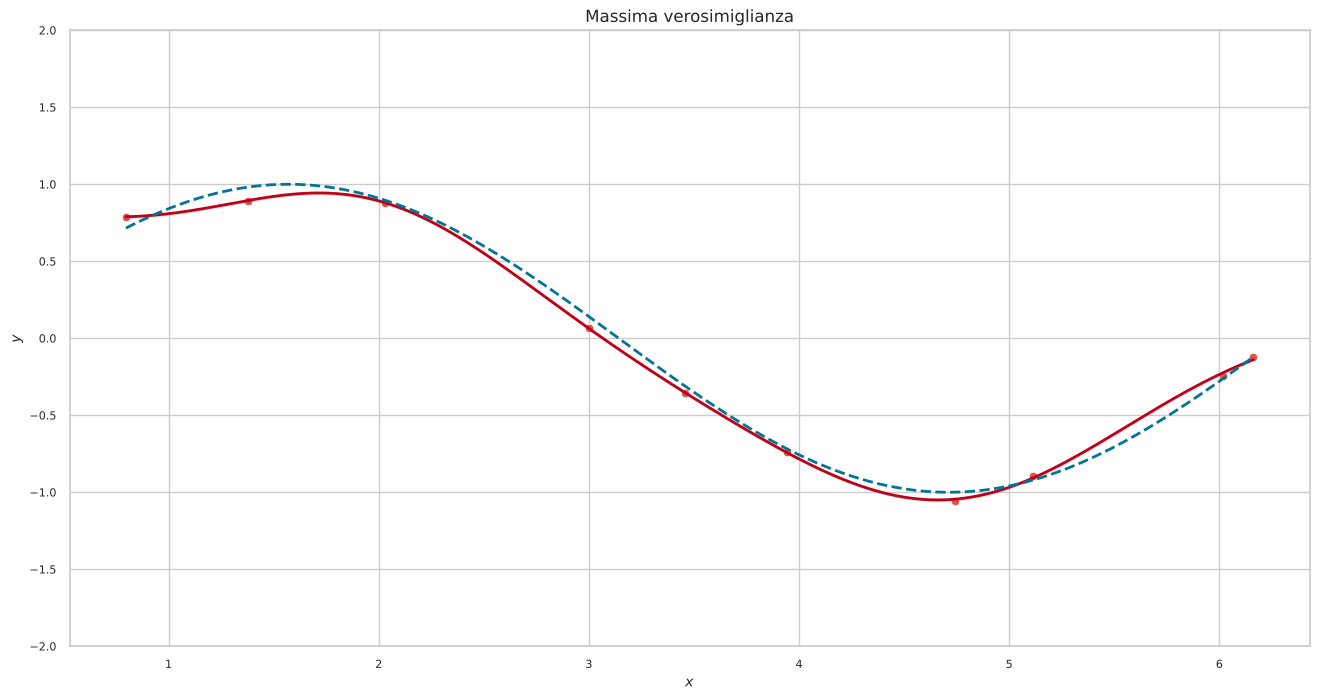

In [9]:
# stima di massima verosimiglianza dei parametri (minimi quadrati)
w_ml = np.linalg.lstsq(X_t, t_t, rcond=None)[0]
# stima di massima verosimiglianza della precisione del rumore
beta_ml = 1.0/np.mean((t_t - X_t.dot(w_ml))**2)
print('deviazione standard stimata del rumore: {0:.4f} (vera: {1:.4f})'.format(1/np.sqrt(beta_ml), noise))
print('norma dei coefficienti: {0:.2f}'.format(np.linalg.norm(w_ml)))

# predizioni e banda a una deviazione standard
m_ml = phix.dot(w_ml).ravel()
sd_ml = np.full_like(m_ml, 1/np.sqrt(beta_ml))

fig = plt.figure(figsize=(16,8))
ax = fig.gca()
sns.lineplot(x=np.ravel(xx), y=np.ravel(m_ml), linestyle='-', color=colors[9], alpha=1, ax=ax)
ax.fill_between(xx, m_ml-sd_ml, m_ml+sd_ml, facecolor=colors[9], alpha=.15)
sns.scatterplot(x=np.ravel(X[l:]), y=np.ravel(t[l:]), color=colors[1], marker='o', alpha=1, ax=ax)
sns.scatterplot(x=np.ravel(X[:l]), y=np.ravel(t[:l]), color=colors[2], marker='o', alpha=1, ax=ax)
sns.lineplot(x=np.ravel(xx), y=np.ravel(f(xx)), linestyle='--', color=colors[1], alpha=1, ax=ax)
plt.ylim(-2, 2)
plt.xlabel(u'$x$', fontsize=10)
plt.ylabel(u'$y$', fontsize=10)
plt.title('Massima verosimiglianza', fontsize=12)
plt.show()

Con $8$ parametri e soli $10$ elementi, la massima verosimiglianza è molto vicina a un'interpolazione: la curva passa quasi esattamente per i punti e, dove i dati mancano, può allontanarsi dalla funzione vera o oscillare (l'entità dipende dal campione generato: rieseguendo il notebook si ottengono situazioni diverse); i coefficienti assumono valori più grandi di quelli della stima MAP, e si compensano a vicenda. È l'**overfitting** discusso nelle note.

Anche la stima del rumore ne risente: i residui sul training set sono piccolissimi, e la deviazione standard stimata è molto inferiore a quella vera. La banda di incertezza è quindi stretta **ovunque**, anche dove la curva si allontana dalla funzione vera: il modello è sicuro di sé esattamente dove sbaglia di più. È il limite della predizione per massima verosimiglianza: un unico valore dei parametri, stimato senza alcun vincolo, e un'incertezza che riflette solo il rumore, per di più sottostimato.

## Predizione MAP

L'approccio bayesiano tratta i parametri come variabili casuali, con un **prior** che esprime ciò che si crede di essi prima di osservare i dati. Con il prior gaussiano isotropo $p(\mathbf{w}\mid\alpha)=\mathcal{N}(\mathbf{0},\alpha^{-1}\mathbf{I})$, che non preferisce né valori positivi né negativi e favorisce valori piccoli, la regola di Bayes dà il **posterior**
$$p(\mathbf{w}\mid\mathbf{X},\mathbf{t})\propto p(\mathbf{t}\mid\mathbf{X},\mathbf{w},\beta)\,p(\mathbf{w}\mid\alpha).$$
Quando serve un solo vettore di parametri, si sceglie la **moda** del posterior, la stima **maximum a posteriori**:
$$\mathbf{w}_{MAP}=\underset{\mathbf{w}}{\mathrm{argmax}}\bigl(\log p(\mathbf{t}\mid\mathbf{X},\mathbf{w},\beta)+\log p(\mathbf{w}\mid\alpha)\bigr)=\underset{\mathbf{w}}{\mathrm{argmin}}\Bigl(\frac\beta2\sum_{i=1}^l r_i^2+\frac\alpha2\mathbf{w}^T\mathbf{w}\Bigr).$$
Dividendo per $\beta$, è la funzione obiettivo della **ridge regression** con $\lambda=\alpha/\beta$: la regolarizzazione, introdotta nelle note come penalità sui pesi, è la conseguenza di un prior gaussiano sui parametri. La soluzione è
$$\mathbf{w}_{MAP}=\Bigl(\frac\alpha\beta\mathbf{I}+\boldsymbol\Phi^T\boldsymbol\Phi\Bigr)^{-1}\boldsymbol\Phi^T\mathbf{t},$$
e la predizione è $\mathcal{N}\bigl(t\mid\mathbf{w}_{MAP}^T\boldsymbol\phi(x),\beta^{-1}\bigr)$, con la precisione del rumore $\beta$ fissata.

lambda = 0.0040
norma dei coefficienti: 1.37


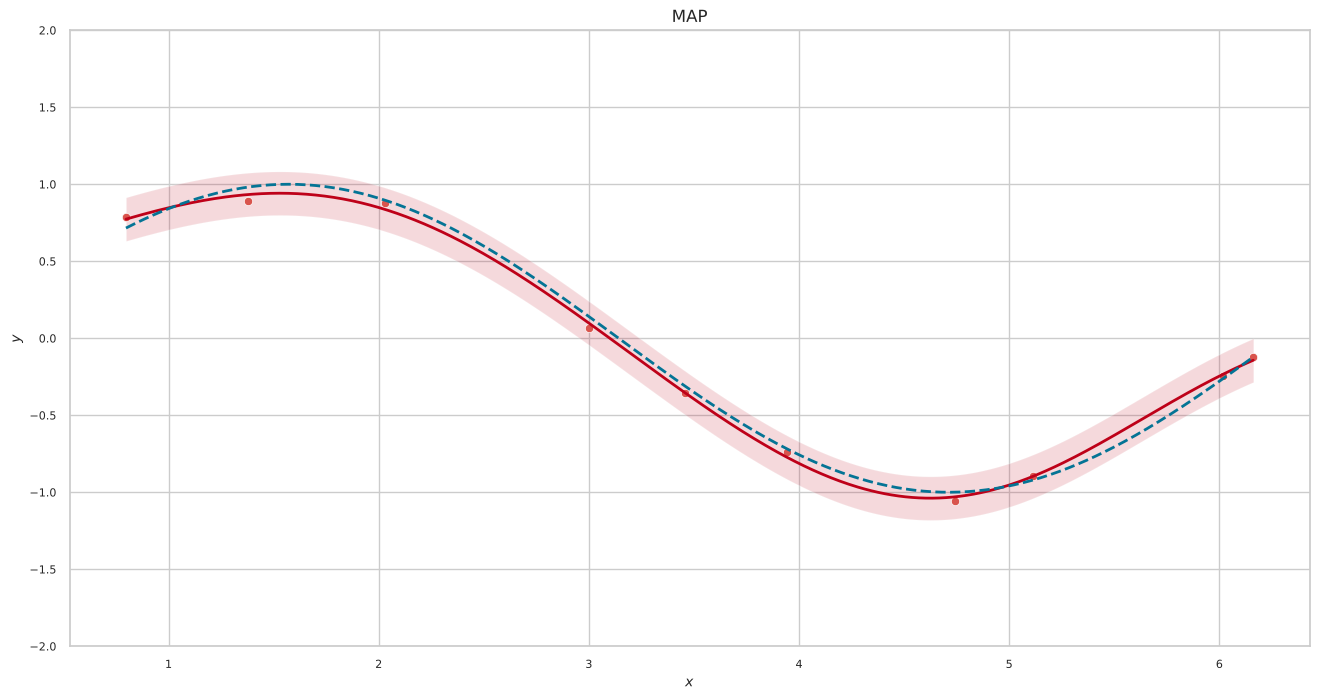

In [10]:
# stima MAP: ridge regression con lambda = alfa/beta
lam = alfa/beta
w_map = np.linalg.solve(lam*np.eye(d) + X_t.T.dot(X_t), X_t.T.dot(t_t))
print('lambda = {0:.4f}'.format(lam))
print('norma dei coefficienti: {0:.2f}'.format(np.linalg.norm(w_map)))

# predizioni e banda a una deviazione standard
m_map = phix.dot(w_map).ravel()
sd_map = np.full_like(m_map, 1/np.sqrt(beta))

fig = plt.figure(figsize=(16,8))
ax = fig.gca()
sns.lineplot(x=np.ravel(xx), y=np.ravel(m_map), linestyle='-', color=colors[9], alpha=1, ax=ax)
ax.fill_between(xx, m_map-sd_map, m_map+sd_map, facecolor=colors[9], alpha=.15)
sns.scatterplot(x=np.ravel(X[l:]), y=np.ravel(t[l:]), color=colors[1], marker='o', alpha=1, ax=ax)
sns.scatterplot(x=np.ravel(X[:l]), y=np.ravel(t[:l]), color=colors[2], marker='o', alpha=1, ax=ax)
sns.lineplot(x=np.ravel(xx), y=np.ravel(f(xx)), linestyle='--', color=colors[1], alpha=1, ax=ax)
plt.ylim(-2, 2)
plt.xlabel(u'$x$', fontsize=10)
plt.ylabel(u'$y$', fontsize=10)
plt.title('MAP', fontsize=12)
plt.show()

Il prior **trattiene** i coefficienti, la cui norma è molto più piccola di quella della stima ML: la curva non è più costretta a passare esattamente per i punti, e le oscillazioni tra di essi si attenuano. MAP resiste all'overfitting meglio della massima verosimiglianza, soprattutto con pochi dati.

La banda di incertezza, però, ha ancora ampiezza **costante**, pari a $\pm1/\sqrt\beta$: riflette solo il rumore, e non dipende né dal numero di dati né dalla posizione rispetto a essi. MAP usa infatti ancora un solo vettore di parametri, e ignora l'incertezza che resta su di esso. Per tenerne conto bisogna usare l'intero posterior.

## Predizione pienamente bayesiana: la distribuzione predittiva

La predizione pienamente bayesiana usa l'intero posterior. Il prior gaussiano è **coniugato** alla verosimiglianza gaussiana, e il posterior è ancora gaussiano,
$$p(\mathbf{w}\mid\mathbf{X},\mathbf{t})=\mathcal{N}(\mathbf{w}\mid\mathbf{m}_p,\boldsymbol\Sigma_p),\qquad \boldsymbol\Sigma_p=\bigl(\alpha\mathbf{I}+\beta\boldsymbol\Phi^T\boldsymbol\Phi\bigr)^{-1},\qquad \mathbf{m}_p=\beta\,\boldsymbol\Sigma_p\boldsymbol\Phi^T\mathbf{t},$$
con media pari alla stima MAP, $\mathbf{m}_p=\mathbf{w}_{MAP}$. Invece di usare un solo valore dei parametri, la **distribuzione predittiva** media le predizioni di tutti i modelli, pesandoli con il posterior:
$$p(t\mid x,\mathbf{X},\mathbf{t})=\int p(t\mid x,\mathbf{w},\beta)\,p(\mathbf{w}\mid\mathbf{X},\mathbf{t})\,d\mathbf{w}=\mathcal{N}\bigl(t\mid m(x),\sigma^2(x)\bigr),$$
$$m(x)=\mathbf{m}_p^T\boldsymbol\phi(x),\qquad \sigma^2(x)=\underbrace{\frac1\beta}_{\text{rumore}}+\underbrace{\boldsymbol\phi(x)^T\boldsymbol\Sigma_p\boldsymbol\phi(x)}_{\text{incertezza sui parametri}}.$$
La media coincide con la predizione MAP; la varianza ha due componenti: l'incertezza **aleatoria**, dovuta al rumore e presente anche se i parametri fossero noti, e l'incertezza **epistemica**, dovuta alla conoscenza incompleta dei parametri, che si riduce all'aumentare dei dati, ed è piccola vicino ai punti osservati e grande lontano da essi.

Le due funzioni seguenti calcolano media e varianza della distribuzione predittiva in un punto $v$. Usano le variabili globali `m` e `s`, calcolate nella cella successiva. (La media è convertita in scalare con `.item()`: le versioni recenti di `numpy` non accettano che una funzione vettorizzata con `np.vectorize` restituisca un array.)

In [11]:
# media della distribuzione predittiva
def m_pred(v):
    return m.T.dot(vphi(v,d,domain)).item()
    
# varianza della distribuzione predittiva    
def var_pred(v):
    v1=vphi(v,d,domain)
    return 1.0/beta+v1.dot(s.dot(v1.T))

## Il posterior

Calcoliamo covarianza e media del posterior sullo stesso training set usato per ML e MAP.

In [12]:
# derivazione di media e matrice di covarianza a posteriori
s = np.linalg.inv(alfa*np.eye(d)+beta*np.dot(X_t.T,X_t))
m=beta*s.dot(X_t.T.dot(t_t))

## Il grafico

Per ogni punto di una griglia fine calcoliamo media e varianza predittive. La curva continua è la media $m(x)$, la banda colorata copre l'intervallo $m(x)\pm\sigma(x)$, a una deviazione standard dalla media; la curva tratteggiata è la funzione vera $\sin(x)$, i punti sono il training set.

Come leggere il grafico:

- vicino ai punti del training set la banda è stretta: lì i dati hanno vincolato i parametri, e l'incertezza epistemica è piccola;
- tra punti lontani tra loro, e ai bordi del dominio, la banda si allarga: lì i dati non danno informazione, e la predizione è incerta;
- la larghezza minima della banda non scende mai sotto $1/\sqrt\beta$: è l'incertezza aleatoria dovuta al rumore, che nessuna quantità di dati può eliminare.

Questa è la caratteristica che distingue la predizione pienamente bayesiana dalla stima di massima verosimiglianza o MAP, in cui la varianza predittiva è costante, pari a $1/\beta$, ovunque.

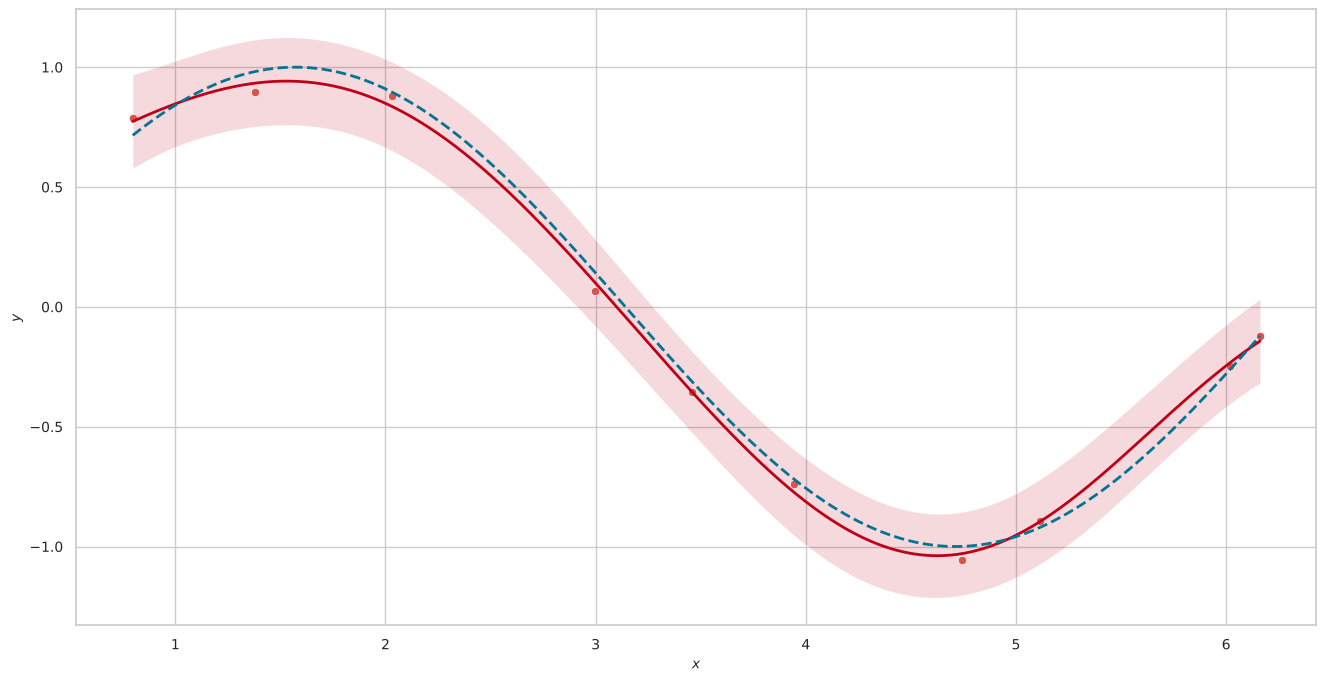

In [13]:
# insieme dei valori considerati per il plot
xx=np.linspace(min(X),max(X),500)
# loro immagini per il calcolo della regressione
phix=vphi(xx,d,domain)

# calcolo di media e varianza della distribuzione predittiva per tutti i valori
mx = np.vectorize(m_pred)(xx)
sx= np.vectorize(var_pred)(xx)

# visualizzazione
fig = plt.figure(figsize=(16,8))
ax = fig.gca()
# plot della media
sns.lineplot(x=np.ravel(xx), y=np.ravel(mx), linestyle='-', color=colors[9], alpha=1, ax=ax)
# riempimento della regione a distanza minore di una sd dalla media
ax.fill_between(xx, mx-np.sqrt(sx), mx+np.sqrt(sx), facecolor=colors[9], alpha=.15)
# elementi dell'insieme
sns.scatterplot(x=np.ravel(X[l:]), y=np.ravel(t[l:]), color=colors[1], marker='o', alpha=1, ax=ax)
sns.scatterplot(x=np.ravel(X[:l]), y=np.ravel(t[:l]), color=colors[2], marker='o', alpha=1, ax=ax)
# plot funzione originale
sns.lineplot(x=np.ravel(xx), y=np.ravel(f(xx)), linestyle='--', color=colors[1], alpha=1, ax=ax)
plt.xlabel(u'$x$', fontsize=10)
plt.ylabel(u'$y$', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()


## Confronto tra i tre approcci

I tre grafici affiancati riassumono le differenze tra i tre approcci:

- la **massima verosimiglianza** segue i dati senza vincoli, e con pochi dati e molti parametri va in overfitting; la sua banda è costante e, stimata sui residui di training, troppo stretta;
- **MAP** regolarizza la stima grazie al prior, e la curva è più regolare; la banda è costante, pari al solo rumore assunto;
- la predizione **pienamente bayesiana** ha la stessa media di MAP, ma una banda che si allarga dove i dati mancano, ai bordi e tra punti distanti, e si restringe vicino ai dati: è l'unica che segnala dove il modello non sa.

Al crescere del numero di dati, il posterior si concentra, il termine epistemico si annulla e le tre predizioni tendono a coincidere: le differenze contano soprattutto quando i dati sono pochi rispetto ai parametri, come qui.

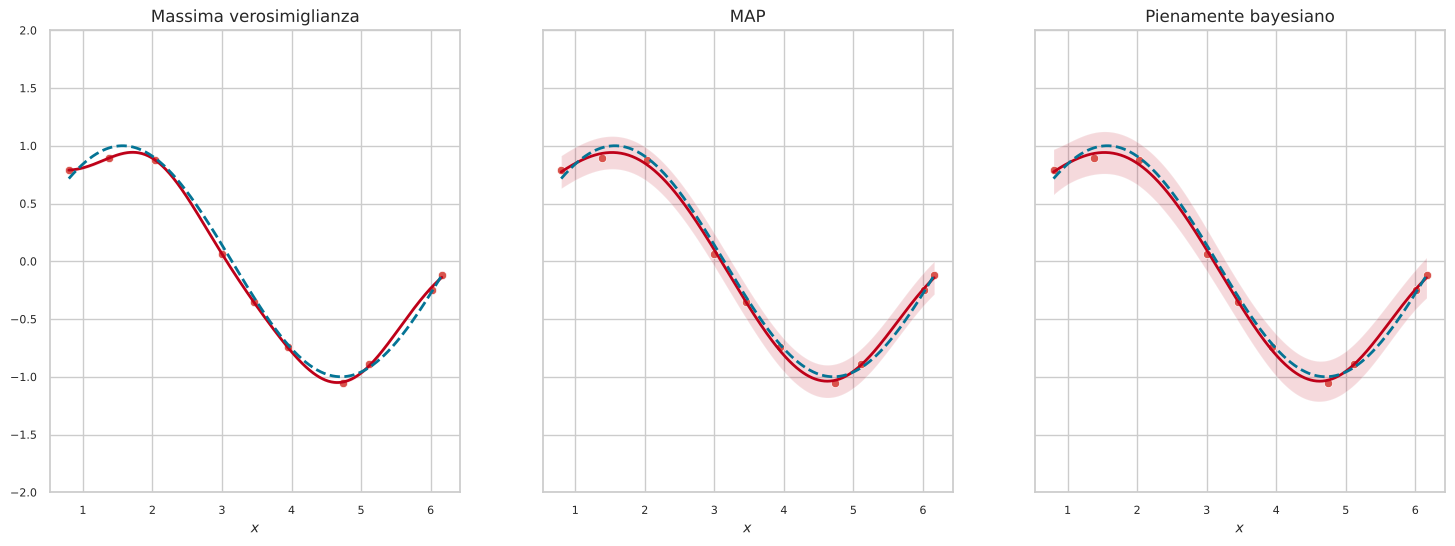

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(18,6), sharey=True)
for ax, (mean, sd, title) in zip(axs, [(m_ml, sd_ml, 'Massima verosimiglianza'),
                                       (m_map, sd_map, 'MAP'),
                                       (mx, np.sqrt(sx), 'Pienamente bayesiano')]):
    sns.lineplot(x=np.ravel(xx), y=np.ravel(mean), linestyle='-', color=colors[9], ax=ax)
    ax.fill_between(xx, mean-sd, mean+sd, facecolor=colors[9], alpha=.15)
    sns.scatterplot(x=np.ravel(X[:l]), y=np.ravel(t[:l]), color=colors[2], marker='o', ax=ax)
    sns.lineplot(x=np.ravel(xx), y=np.ravel(f(xx)), linestyle='--', color=colors[1], ax=ax)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('$x$')
axs[0].set_ylim(-2, 2)
plt.show()

# Loss lineare e rumore di Laplace

Fin qui il modello probabilistico ha assunto rumore **gaussiano**, che induce la loss quadratica. Nelle note si discute un'alternativa: la loss **lineare**, o assoluta, $L(y,t)=|y-t|$, che penalizza i residui in proporzione alla loro ampiezza e non al loro quadrato. Con questa crescita lineare nessun singolo errore grande può dominare la somma, e la loss è molto più **robusta** rispetto agli outlier.

Come la loss quadratica corrisponde al rumore gaussiano, la loss assoluta corrisponde a un modello di rumore additivo con distribuzione di **Laplace** di scala $b>0$:
$$p(t\mid x,\mathbf{w},b)=\frac1{2b}\exp\Bigl(-\frac{|t-\mathbf{w}^T\boldsymbol\phi(x)|}{b}\Bigr),\qquad -\log p(t\mid x,\mathbf{w},b)=\frac{|t-\mathbf{w}^T\boldsymbol\phi(x)|}{b}+\log(2b).$$
Rispetto a una gaussiana con la stessa varianza ($\sigma^2=2b^2$), la densità di Laplace ha un picco più stretto in zero e code più pesanti, che decadono come $e^{-|\varepsilon|}$ invece che come $e^{-\varepsilon^2}$: residui grandi sono rari ma plausibili, e non vanno penalizzati pesantemente. Il predittore ottimo non è più la media condizionata ma la **mediana** condizionata.

In questa sezione ripercorriamo i tre approcci, massima verosimiglianza, MAP e pienamente bayesiano, con il rumore di Laplace, e confrontiamo i risultati con quelli del rumore gaussiano: prima sullo stesso training set, poi su un dataset contenente alcuni **outlier**. Vedremo anche che, perso il caso gaussiano, perdiamo le **forme chiuse**: ogni approccio richiede un metodo numerico.

## Massima verosimiglianza con rumore di Laplace

La log-verosimiglianza è
$$\log p(\mathbf{t}\mid\mathbf{X},\mathbf{w},b)=-\frac1b\sum_{i=1}^l|r_i|-l\log(2b),$$
e, poiché $\mathbf{w}$ compare solo nel primo termine, la stima di massima verosimiglianza minimizza la **somma dei valori assoluti dei residui** (*least absolute deviations*). Annullando la derivata rispetto a $b$ si ottiene la stima della scala del rumore, $b_{ML}=\frac1l\sum_i|r_i|$, la media dei valori assoluti dei residui.

La funzione obiettivo è convessa ma non differenziabile dove un residuo si annulla, e non esiste una formula chiusa analoga alle equazioni normali. Il problema si risolve però esattamente come **programma lineare**, introducendo variabili ausiliarie $u_i\geq|r_i|$:
$$\min_{\mathbf{w},\mathbf{u}}\sum_{i=1}^lu_i\qquad\text{con}\quad \boldsymbol\Phi\mathbf{w}-\mathbf{u}\leq\mathbf{t},\quad -\boldsymbol\Phi\mathbf{w}-\mathbf{u}\leq-\mathbf{t},$$
risolto qui con `scipy.optimize.linprog`. Una proprietà della soluzione: esiste sempre un minimo in cui almeno tanti residui quanti sono i parametri sono esattamente nulli, cioè la curva **interpola** un sottoinsieme dei punti.

In [15]:
from scipy.optimize import linprog

def ml_laplace(Phi, t):
    # stima ML con rumore di Laplace: minimizzazione di sum |r_i| come programma lineare
    n, d = Phi.shape
    t = t.ravel()
    c = np.r_[np.zeros(d), np.ones(n)]
    A = np.block([[Phi, -np.eye(n)], [-Phi, -np.eye(n)]])
    b_ub = np.r_[t, -t]
    res = linprog(c, A_ub=A, b_ub=b_ub, bounds=[(None, None)]*d + [(0, None)]*n, method='highs')
    w = res.x[:d]
    b_ml = np.mean(np.abs(t - Phi.dot(w)))
    return w, b_ml

## MAP con rumore di Laplace

Con lo stesso prior gaussiano $\mathcal{N}(\mathbf{0},\alpha^{-1}\mathbf{I})$, la stima MAP minimizza
$$\frac1b\sum_{i=1}^l|r_i|+\frac\alpha2\mathbf{w}^T\mathbf{w}:$$
una loss assoluta con una penalità quadratica sui pesi. Per confrontare i due modelli di rumore a parità di varianza, fissiamo la scala in modo che $2b^2=1/\beta$, cioè $b=1/\sqrt{2\beta}$: i due modelli assumono la stessa deviazione standard del rumore, $1/\sqrt\beta\approx0.14$.

Anche qui non c'è una forma chiusa. Un metodo semplice e istruttivo è l'**iteratively reweighted least squares** (IRLS): poiché $|r_i|=r_i^2/|r_i|$, la loss assoluta è una loss quadratica **pesata**, con peso $1/|r_i|$ per ciascun elemento. Partendo dalla soluzione quadratica, si alternano il calcolo dei pesi sui residui correnti e la soluzione di un problema di minimi quadrati pesati e regolarizzati,
$$\mathbf{w}\leftarrow\Bigl(\alpha\mathbf{I}+\frac1b\boldsymbol\Phi^T\mathbf{D}\boldsymbol\Phi\Bigr)^{-1}\frac1b\boldsymbol\Phi^T\mathbf{D}\mathbf{t},\qquad \mathbf{D}=\mathrm{diag}\Bigl(\frac1{|r_i|}\Bigr),$$
fino a convergenza. L'iterazione rende evidente il meccanismo della robustezza: gli elementi con **residuo grande ricevono peso piccolo**, e un outlier, che con la loss quadratica tira la curva verso di sé con una forza proporzionale al residuo, qui conta tanto quanto un elemento qualsiasi.

In [16]:
def map_laplace(Phi, t, alfa, b, n_iter=1000, eps=1e-8, tol=1e-9):
    # stima MAP con rumore di Laplace e prior gaussiano, mediante IRLS
    t = t.ravel()
    d = Phi.shape[1]
    # punto di partenza: soluzione con loss quadratica (ridge)
    w = np.linalg.solve(alfa*np.eye(d) + Phi.T.dot(Phi)/b, Phi.T.dot(t)/b)
    for k in range(n_iter):
        r = np.abs(t - Phi.dot(w))
        D = 1/np.maximum(r, eps)          # pesi: inversi dei residui
        w_new = np.linalg.solve(alfa*np.eye(d) + (Phi.T*D).dot(Phi)/b, (Phi.T*D).dot(t)/b)
        if np.max(np.abs(w_new - w)) < tol:
            return w_new
        w = w_new
    return w

## Predizione pienamente bayesiana con rumore di Laplace

Il prior gaussiano **non è coniugato** alla verosimiglianza di Laplace: il posterior
$$p(\mathbf{w}\mid\mathbf{X},\mathbf{t})\propto\exp\Bigl(-\frac1b\sum_{i=1}^l|r_i|-\frac\alpha2\mathbf{w}^T\mathbf{w}\Bigr)$$
non è gaussiano, e né la sua normalizzazione né la distribuzione predittiva hanno una forma chiusa. Come discusso nelle note, una soluzione generale è il campionamento con **Markov chain Monte Carlo**: si genera una sequenza di vettori $\mathbf{w}^{(1)},\ldots,\mathbf{w}^{(S)}$ distribuiti, dopo un periodo iniziale, secondo il posterior, e si approssimano gli integrali con medie sui campioni.

Usiamo l'algoritmo di **Metropolis**: a ogni passo si propone un nuovo punto $\mathbf{w}'=\mathbf{w}+\boldsymbol\epsilon$, con $\boldsymbol\epsilon$ gaussiano, e lo si accetta con probabilità $\min\bigl(1,p(\mathbf{w}'\mid\cdot)/p(\mathbf{w}\mid\cdot)\bigr)$; il rapporto non richiede la costante di normalizzazione del posterior. La covarianza della proposta è presa, opportunamente scalata, da quella del posterior gaussiano con la stessa varianza del rumore, che ne dà una buona idea della forma.

La distribuzione predittiva è una **miscela** di distribuzioni di Laplace, una per campione. La sua media è $m(x)=\frac1S\sum_s\mathbf{w}^{(s)T}\boldsymbol\phi(x)$, e la sua varianza ha le stesse due componenti del caso gaussiano:
$$\sigma^2(x)=\underbrace{2b^2}_{\text{rumore}}+\underbrace{\frac1S\sum_s\bigl(\mathbf{w}^{(s)T}\boldsymbol\phi(x)-m(x)\bigr)^2}_{\text{incertezza sui parametri}}.$$

In [17]:
def mcmc_laplace(Phi, t, alfa, b, w_start, n_iter=60000, burn=10000, thin=10):
    # campionamento del posterior (verosimiglianza di Laplace, prior gaussiano) con Metropolis
    t = t.ravel()
    d = Phi.shape[1]
    log_post = lambda w: -np.abs(t - Phi.dot(w)).sum()/b - alfa/2*w.dot(w)
    # covarianza della proposta: posterior gaussiano con la stessa varianza del rumore (2b^2), scalato
    S_g = np.linalg.inv(alfa*np.eye(d) + Phi.T.dot(Phi)/(2*b*b))
    L = np.linalg.cholesky(2.38**2/d*S_g)
    w = w_start.copy()
    lp = log_post(w)
    accepted = 0
    samples = []
    for k in range(n_iter):
        w_prop = w + L.dot(np.random.standard_normal(d))
        lp_prop = log_post(w_prop)
        if np.log(np.random.rand()) < lp_prop - lp:
            w, lp = w_prop, lp_prop
            accepted += 1
        if k >= burn and (k - burn) % thin == 0:
            samples.append(w.copy())
    return np.array(samples), accepted/n_iter

## I sei predittori

Per confrontare i due modelli di rumore conviene raccogliere i tre approcci in un'unica funzione per ciascun modello, che restituisce, per ogni punto della griglia, la media e la deviazione standard della distribuzione predittiva. Per il caso gaussiano le formule sono quelle delle sezioni precedenti; la funzione `plot_grid` disegna i sei predittori in una griglia, con il modello gaussiano nella prima riga e quello di Laplace nella seconda.

In [18]:
def predictors_gauss(Phi, t, phix, alfa, beta):
    d = Phi.shape[1]
    out = {}
    # massima verosimiglianza
    w = np.linalg.lstsq(Phi, t, rcond=None)[0].ravel()
    sd = np.sqrt(np.mean((t.ravel() - Phi.dot(w))**2))
    out['ML'] = (phix.dot(w), np.full(phix.shape[0], sd))
    # MAP
    w = np.linalg.solve(alfa/beta*np.eye(d) + Phi.T.dot(Phi), Phi.T.dot(t)).ravel()
    out['MAP'] = (phix.dot(w), np.full(phix.shape[0], 1/np.sqrt(beta)))
    # pienamente bayesiano
    S = np.linalg.inv(alfa*np.eye(d) + beta*Phi.T.dot(Phi))
    m_p = beta*S.dot(Phi.T.dot(t)).ravel()
    var = 1/beta + np.einsum('ij,jk,ik->i', phix, S, phix)
    out['Bayes'] = (phix.dot(m_p), np.sqrt(var))
    return out

def predictors_laplace(Phi, t, phix, alfa, b):
    out = {}
    # massima verosimiglianza
    w, b_ml = ml_laplace(Phi, t)
    out['ML'] = (phix.dot(w), np.full(phix.shape[0], np.sqrt(2)*b_ml))
    # MAP
    w_map = map_laplace(Phi, t, alfa, b)
    out['MAP'] = (phix.dot(w_map), np.full(phix.shape[0], np.sqrt(2)*b))
    # pienamente bayesiano (MCMC)
    samples, acc = mcmc_laplace(Phi, t, alfa, b, w_map)
    preds = samples.dot(phix.T)                      # una riga per campione
    out['Bayes'] = (preds.mean(axis=0), np.sqrt(2*b*b + preds.var(axis=0)))
    print('Metropolis: tasso di accettazione {0:.2f}, {1:d} campioni'.format(acc, len(samples)))
    return out

def plot_grid(res_g, res_l, Xtr, ttr, title):
    fig, axs = plt.subplots(2, 3, figsize=(18,10), sharex=True, sharey=True)
    names = {'ML': 'massima verosimiglianza', 'MAP': 'MAP', 'Bayes': 'pienamente bayesiano'}
    for row, (res, noise_name) in enumerate([(res_g, 'gaussiano'), (res_l, 'Laplace')]):
        for col, key in enumerate(['ML', 'MAP', 'Bayes']):
            ax = axs[row, col]
            mean, sd = res[key]
            sns.lineplot(x=np.ravel(xx), y=np.ravel(mean), linestyle='-', color=colors[9], ax=ax)
            ax.fill_between(xx, mean-sd, mean+sd, facecolor=colors[9], alpha=.15)
            sns.scatterplot(x=np.ravel(Xtr), y=np.ravel(ttr), color=colors[2], marker='o', s=25, ax=ax)
            sns.lineplot(x=np.ravel(xx), y=np.ravel(f(xx)), linestyle='--', color=colors[1], ax=ax)
            ax.set_title('{0}, rumore {1}'.format(names[key], noise_name), fontsize=11)
    axs[0,0].set_ylim(-2, 3)
    plt.suptitle(title, fontsize=13)
    plt.show()

def errors_table(res_g, res_l):
    # errore delle predizioni rispetto alla funzione vera sulla griglia
    print('{0:<10}{1:<22}{2:>10}{3:>10}'.format('rumore', 'approccio', 'RMSE', 'MAE'))
    for noise_name, res in [('gauss', res_g), ('laplace', res_l)]:
        for key in ['ML', 'MAP', 'Bayes']:
            e = res[key][0] - f(xx)
            print('{0:<10}{1:<22}{2:>10.4f}{3:>10.4f}'.format(noise_name, key, np.sqrt(np.mean(e**2)), np.mean(np.abs(e))))

## Confronto sullo stesso training set

Applichiamo i sei predittori al training set usato finora, con gli stessi $\alpha$ e $\beta$, e con $b=1/\sqrt{2\beta}$ per il modello di Laplace.

Metropolis: tasso di accettazione 0.16, 5000 campioni


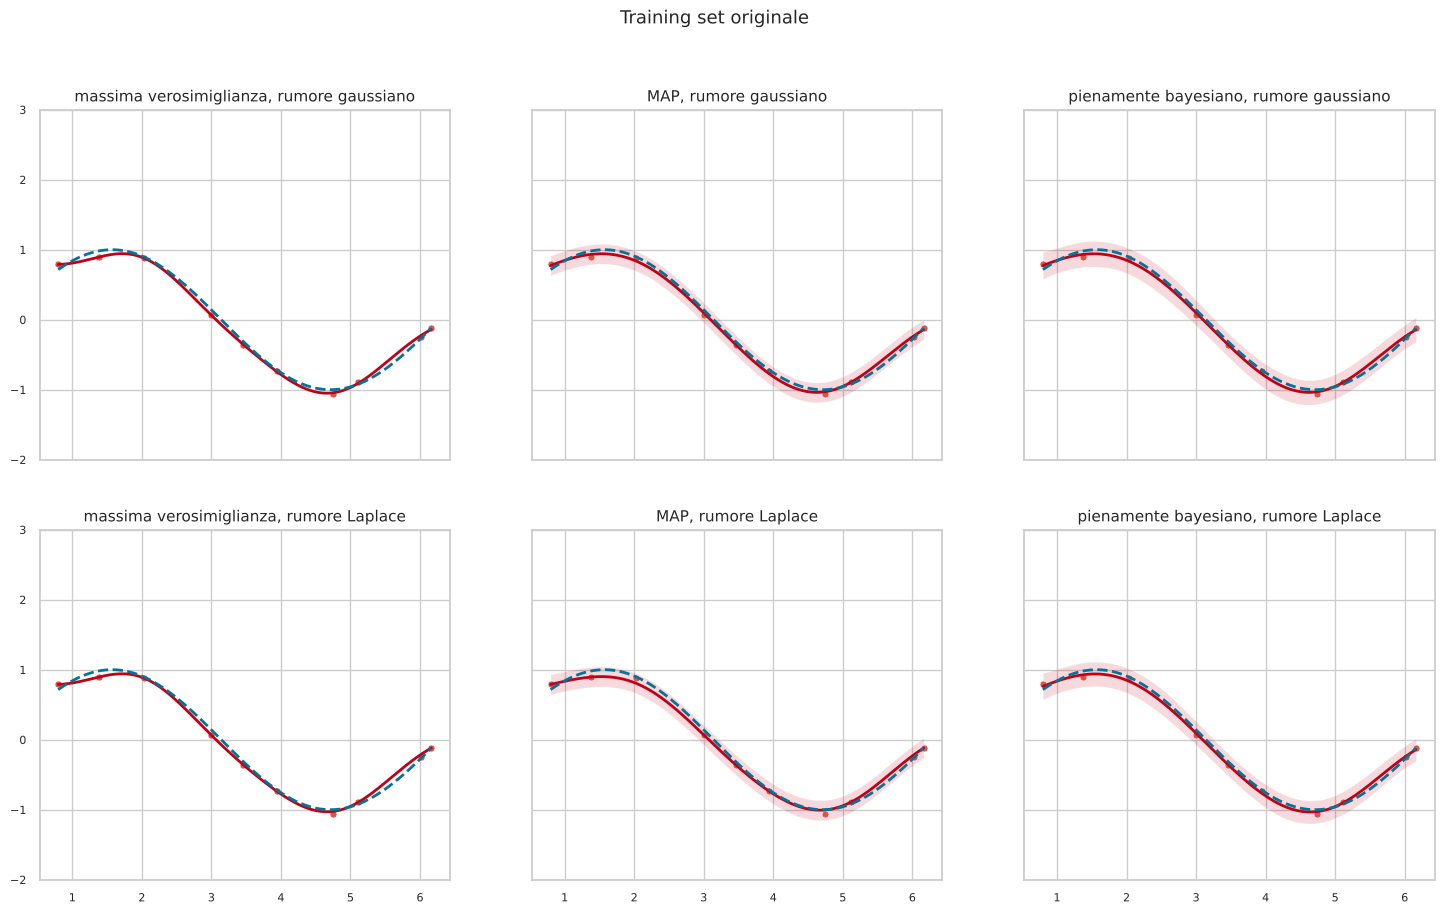

rumore    approccio                   RMSE       MAE
gauss     ML                        0.0545    0.0487
gauss     MAP                       0.0499    0.0467
gauss     Bayes                     0.0499    0.0467
laplace   ML                        0.0549    0.0477
laplace   MAP                       0.0617    0.0533
laplace   Bayes                     0.0479    0.0450


In [19]:
b_lap = 1/np.sqrt(2*beta)
res_g = predictors_gauss(X_t, t_t, phix, alfa, beta)
res_l = predictors_laplace(X_t, t_t, phix, alfa, b_lap)
plot_grid(res_g, res_l, X[:l], t[:l], 'Training set originale')
errors_table(res_g, res_l)

Su questi dati, generati con rumore gaussiano piccolo e senza outlier, i due modelli danno risultati **simili**, e le differenze principali restano quelle tra gli approcci già viste per il caso gaussiano:

- la **massima verosimiglianza** con loss assoluta interpola ancora più strettamente i dati: la soluzione del programma lineare annulla esattamente almeno tanti residui quanti sono i parametri, e la scala stimata $b_{ML}$ è piccolissima, quindi la banda è praticamente assente;
- la stima **MAP** è regolarizzata dal prior in entrambi i casi; con la loss assoluta la curva tende a passare esattamente per alcuni punti, perché il minimo di una somma di valori assoluti si trova tipicamente dove alcuni residui si annullano;
- la predizione **pienamente bayesiana** con rumore di Laplace, calcolata per campionamento, ha una banda che, come nel caso gaussiano, si allarga lontano dai dati; la media dei campioni non coincide più esattamente con la stima MAP, perché il posterior non è gaussiano e la sua media e la sua moda sono diverse.

La tabella riporta l'errore quadratico medio (RMSE) e l'errore assoluto medio (MAE) delle predizioni rispetto alla funzione vera: con dati gaussiani e senza outlier non c'è un vantaggio sistematico della loss assoluta. I valori cambiano a ogni esecuzione, perché dataset e campioni MCMC sono casuali.

## Confronto in presenza di outlier

La differenza tra i due modelli emerge quando i dati contengono **outlier**, osservazioni prodotte da un meccanismo diverso dal rumore ordinario (errori di misura o di trascrizione, eventi rari). Generiamo un nuovo dataset di $30$ punti dalla stessa funzione e con lo stesso rumore, e spostiamo il target di $3$ punti scelti a caso di $+1.5$.

Metropolis: tasso di accettazione 0.16, 5000 campioni


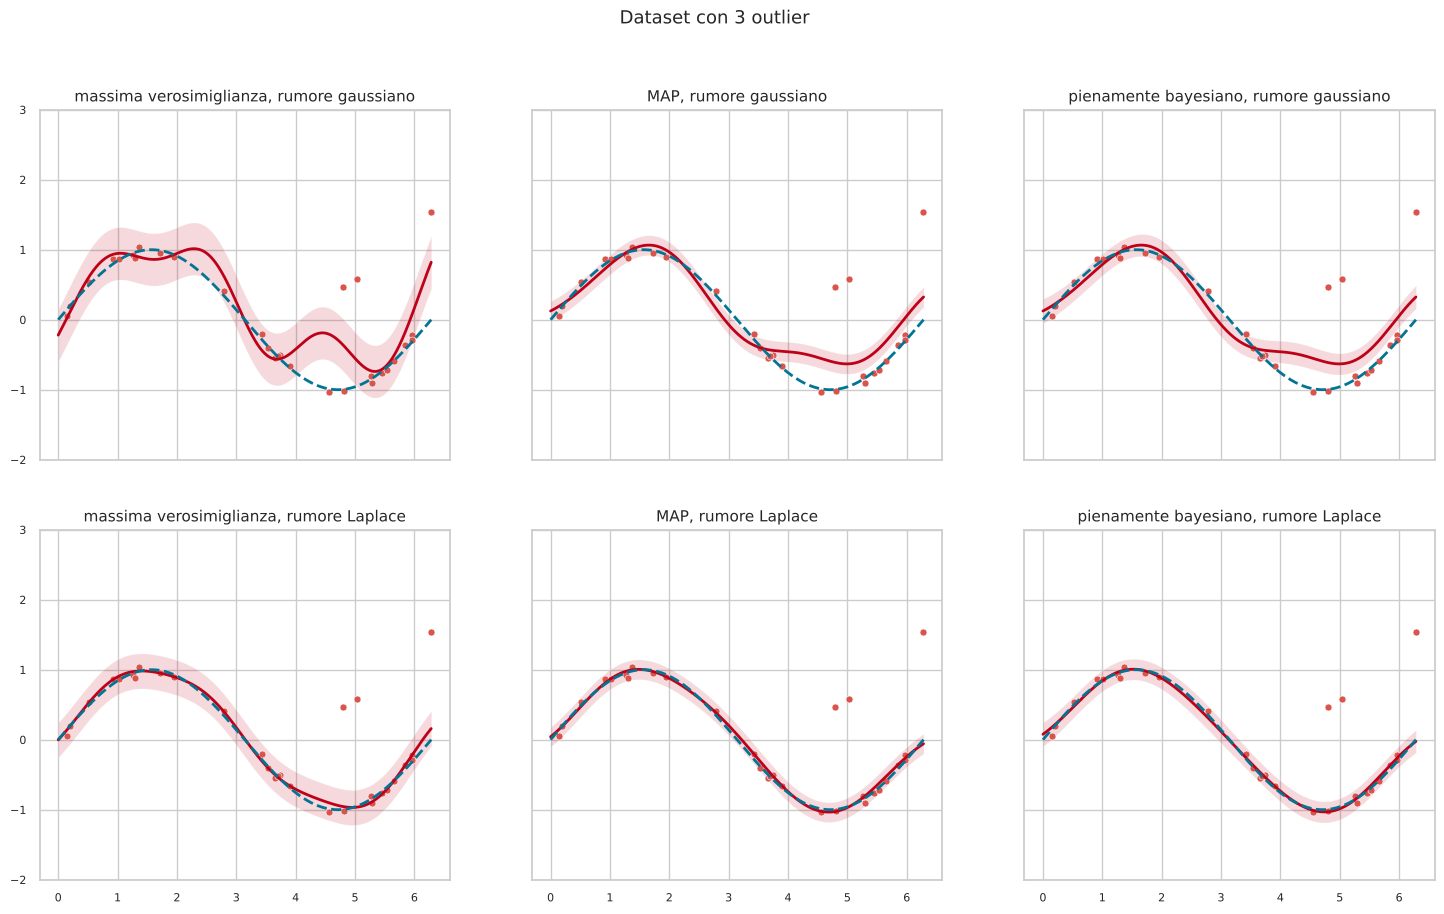

rumore    approccio                   RMSE       MAE
gauss     ML                        0.3335    0.2462
gauss     MAP                       0.2272    0.1812
gauss     Bayes                     0.2272    0.1812
laplace   ML                        0.0537    0.0420
laplace   MAP                       0.0373    0.0304
laplace   Bayes                     0.0292    0.0243


In [20]:
# nuovo dataset con outlier
n2 = 30
X2 = np.random.uniform(domain[0], domain[1], n2)
t2 = (f(X2) + np.random.normal(0, noise, n2)).reshape(-1,1)
outliers = np.random.choice(n2, 3, replace=False)
t2[outliers] += 1.5
Phi2 = vphi(X2, d, domain)

xx = np.linspace(domain[0], domain[1], 500)
phix = vphi(xx, d, domain)

res_g2 = predictors_gauss(Phi2, t2, phix, alfa, beta)
res_l2 = predictors_laplace(Phi2, t2, phix, alfa, b_lap)
plot_grid(res_g2, res_l2, X2, t2, 'Dataset con 3 outlier')
errors_table(res_g2, res_l2)

Con gli outlier la differenza è netta:

- con il **rumore gaussiano** (prima riga) le curve sono **attratte** dagli outlier, in tutti e tre gli approcci: la loss quadratica penalizza un residuo di $1.5$ come $2.25$, e la stima si deforma per ridurre quei pochi residui grandi, peggiorando l'adattamento a tutti gli altri punti. Anche la stima del rumore ne risente: la deviazione standard stimata per massima verosimiglianza è molto più grande di quella vera, e la banda si allarga ovunque;
- con il **rumore di Laplace** (seconda riga) le curve seguono la funzione vera quasi ignorando gli outlier: la loss assoluta penalizza i residui grandi solo linearmente, e, come mostra l'iterazione IRLS, assegna agli outlier un peso piccolo. Il predittore ottimo è la **mediana** condizionata, che non viene spostata da pochi valori estremi, mentre la media sì.

La tabella degli errori rispetto alla funzione vera quantifica il vantaggio della loss assoluta in questa situazione.

Il prezzo della robustezza, come osservato nelle note, è computazionale: la loss assoluta non è differenziabile, non ha soluzione in forma chiusa, richiede la programmazione lineare o metodi iterativi come IRLS, e, nel caso pienamente bayesiano, la perdita della coniugazione costringe a ricorrere al campionamento. Una soluzione intermedia è la **loss di Huber**, quadratica per residui piccoli e lineare per residui grandi, che combina la regolarità della loss quadratica con la robustezza di quella assoluta.